In [ ]:
ΩAZ``` CQ1223#To be copied into each notebook
#imports necessary libraries, connects to google drive COSC74 Project file, defines features, and creates helper methods
import os, re, gc
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB, MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve, classification_report)
from statsmodels.stats.proportion import proportion_confint

from google.colab import drive
drive.mount("/content/drive")

# File locations in Drive
PROJECT_DIR = "/content/drive/MyDrive/COSC74_project"
SUBSET_PATH = f"{PROJECT_DIR}/identity_subset.parquet"     # saved by the Step 1 notebook
SPLITS_PATH = f"{PROJECT_DIR}/splits.csv"                   # saved by the Step 2 notebook
VECTORIZER_PATH = f"{PROJECT_DIR}/tfidf_vectorizer.joblib"  # saved by the Step 2 notebook
RESULTS_DIR = f"{PROJECT_DIR}/results"   # tuned models, thresholds, validation results (Step 3+)
os.makedirs(RESULTS_DIR, exist_ok=True)

SEED = 42
IDENTITY_CATEGORIES = {
    "gender":             ["male", "female", "transgender", "other_gender"],
    "sexual_orientation": ["heterosexual", "homosexual_gay_or_lesbian", "bisexual",
                           "other_sexual_orientation"],
    "religion":           ["christian", "jewish", "muslim", "hindu", "buddhist", "atheist",
                           "other_religion"],
    "race_ethnicity":     ["black", "white", "asian", "latino", "other_race_or_ethnicity"],
    "disability":         ["physical_disability", "intellectual_or_learning_disability",
                           "psychiatric_or_mental_illness", "other_disability"],
}
IDENTITY_COLS = [c for cols in IDENTITY_CATEGORIES.values() for c in cols]
MENTION_COLS = [f"{c}_mentioned" for c in IDENTITY_COLS]
CATEGORY_COLS = [f"{cat}_mentioned" for cat in IDENTITY_CATEGORIES]

def load_data(with_splits=True):
    """Load the identity subset; if with_splits, attach each comment's train/val/test split."""
    data = pd.read_parquet(SUBSET_PATH)
    if with_splits:
        splits = pd.read_csv(SPLITS_PATH)
        data = data.merge(splits, on="id", how="inner")   # keeps only comments that were split
    return data

def get_scores(model, X):
    """Probability of toxic for LR/NB; signed distance from the boundary for LinearSVC."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

def best_f1_threshold(y_true, scores):
    """Threshold that maximizes F1. Only ever call this on validation data."""
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    best = np.argmax(f1[:-1])   # the last precision/recall pair has no threshold
    return thresholds[best], f1[best]

def evaluate(y_true, scores, threshold):
    """ROC-AUC and PR-AUC (no threshold needed) plus accuracy, precision, recall, F1 at a threshold."""
    preds = (scores >= threshold).astype(int)
    return {"roc_auc": roc_auc_score(y_true, scores),
            "pr_auc": average_precision_score(y_true, scores),
            "threshold": threshold,
            "accuracy": accuracy_score(y_true, preds),
            "precision": precision_score(y_true, preds, zero_division=0),
            "recall": recall_score(y_true, preds, zero_division=0),
            "f1": f1_score(y_true, preds, zero_division=0)}

np.random.seed(SEED)
pd.set_option("display.max_columns", 60)
print("Files in project folder:", os.listdir(PROJECT_DIR))

Mounted at /content/drive
Files in project folder: ['all_data.csv', 'identity_individual_annotations.csv', 'sample_submission.csv', 'test.csv', 'test_private_expanded.csv', 'test_public_expanded.csv', 'toxicity_individual_annotations.csv', 'train.csv', 'identity_subset.parquet', 'splits.csv', 'tfidf_vectorizer.joblib', 'results']


In [ ]:
# Load the test set (first time it is used; models and thresholds are already fixed)
df = load_data()
test_df = df[df["split"] == "test"].reset_index(drop=True)

vectorizer = joblib.load(VECTORIZER_PATH)
X_test_vec = vectorizer.transform(test_df["comment_text"])   # transform only, never fit

# Comments that mention no identity: the comparison group
test_df["background"] = ~test_df[MENTION_COLS].any(axis=1)

print(f"Test comments: {len(test_df):,}  (toxic rate {test_df['toxic'].mean():.2%})")
print(f"Background comments (no identity mentioned): {test_df['background'].sum():,}")

Test comments: 40,201  (toxic rate 11.36%)
Background comments (no identity mentioned): 23,276


In [ ]:
# Load the three tuned models and score the test set with each one's validation-chosen threshold
MODELS = {"lr": "Logistic Regression", "nb": "Naive Bayes", "svm": "Linear SVM"}
saved_models = {key: joblib.load(f"{RESULTS_DIR}/{key}_best.joblib") for key in MODELS}

for key, saved in saved_models.items():
    test_df[f"{key}_score"] = get_scores(saved["model"], X_test_vec)
    test_df[f"{key}_pred"] = (test_df[f"{key}_score"] >= saved["threshold"]).astype(int)
    print(f"{MODELS[key]:<20} {saved['config']:<28} threshold={saved['threshold']:.3f}  "
          f"flags {test_df[f'{key}_pred'].mean():.1%} of test comments")

# Save test scores and predictions so later steps don't need to recompute them
keep_cols = (["id", "comment_text", "target", "toxic", "identity_attack", "toxicity_annotator_count"]
             + MENTION_COLS + CATEGORY_COLS + ["background"]
             + [f"{key}_{kind}" for key in MODELS for kind in ("score", "pred")])
test_df[keep_cols].to_parquet(f"{RESULTS_DIR}/test_predictions.parquet", index=False)

Logistic Regression  C=1, class_weight=None       threshold=0.219  flags 13.0% of test comments
Naive Bayes          ComplementNB, alpha=0.1      threshold=0.674  flags 12.7% of test comments
Linear SVM           C=0.1, class_weight=None     threshold=-0.419  flags 11.8% of test comments


In [ ]:
def error_rates(data, mask, pred_col):
    """FPR (non-toxic comments flagged) and FNR (toxic comments missed) for the rows in mask."""
    nontoxic = mask & (data["toxic"] == 0)
    toxic = mask & (data["toxic"] == 1)
    n_nontoxic, n_toxic = int(nontoxic.sum()), int(toxic.sum())
    false_pos = int(data.loc[nontoxic, pred_col].sum())
    false_neg = int((data.loc[toxic, pred_col] == 0).sum())
    return {"n_nontoxic": n_nontoxic, "false_pos": false_pos,
            "fpr": false_pos / n_nontoxic if n_nontoxic else np.nan,
            "n_toxic": n_toxic, "false_neg": false_neg,
            "fnr": false_neg / n_toxic if n_toxic else np.nan}

# Groups to compare: reference rows, the 5 categories, then the 24 individual identities
GROUPS = {"overall": ("reference", pd.Series(True, index=test_df.index)),
          "background": ("reference", test_df["background"])}
for col in CATEGORY_COLS:
    GROUPS[col.replace("_mentioned", "")] = ("category", test_df[col])
for col in MENTION_COLS:
    GROUPS[col.replace("_mentioned", "")] = ("identity", test_df[col])

rows = []
for key, model_name in MODELS.items():
    for group, (level, mask) in GROUPS.items():
        rows.append({"model": model_name, "level": level, "group": group,
                     **error_rates(test_df, mask, f"{key}_pred")})
rates = pd.DataFrame(rows)

# Gap from background: positive FPR gap = flagged more often than comments with no identity
background = rates[rates["group"] == "background"].set_index("model")
rates["fpr_gap"] = rates["fpr"] - rates["model"].map(background["fpr"])
rates["fnr_gap"] = rates["fnr"] - rates["model"].map(background["fnr"])
rates["fpr_ratio"] = rates["fpr"] / rates["model"].map(background["fpr"])

rates.to_csv(f"{RESULTS_DIR}/group_error_rates.csv", index=False)

In [ ]:
def wide_table(metric, n_col):
    """One row per group, one column per model, plus the group's sample size."""
    table = rates.pivot(index="group", columns="model", values=metric)[list(MODELS.values())]
    sizes = rates.drop_duplicates("group").set_index("group")[["level", n_col]]
    return sizes.join(table).loc[list(GROUPS)]

print("False positive rate: share of NON-TOXIC comments flagged as toxic")
display(wide_table("fpr", "n_nontoxic").round(4))

print("False negative rate: share of TOXIC comments missed")
display(wide_table("fnr", "n_toxic").round(4))

False positive rate: share of NON-TOXIC comments flagged as toxic


,level,n_nontoxic,Logistic Regression,Naive Bayes,Linear SVM
group,,,,,
overall,reference,35636,0.0642,0.0740,0.0535
background,reference,21481,0.0305,0.0488,0.0272
gender,category,6812,0.1001,0.0985,0.0772
sexual_orientation,category,835,0.2216,0.1365,0.2000
religion,category,5466,0.0957,0.0814,0.0785
race_ethnicity,category,2886,0.2623,0.2464,0.2200
disability,category,395,0.1038,0.1038,0.0759
male,identity,3747,0.1108,0.1102,0.0857
female,identity,4533,0.0885,0.0832,0.0666


False negative rate: share of TOXIC comments missed


,level,n_toxic,Logistic Regression,Naive Bayes,Linear SVM
group,,,,,
overall,reference,4565,0.3601,0.4587,0.3777
background,reference,1795,0.3994,0.4942,0.3900
gender,category,1150,0.3591,0.4513,0.3930
sexual_orientation,category,317,0.3155,0.5331,0.3375
religion,category,853,0.3751,0.5064,0.4115
race_ethnicity,category,1028,0.2529,0.3239,0.2947
disability,category,106,0.2642,0.3208,0.3113
male,identity,645,0.3271,0.4605,0.3736
female,identity,685,0.3810,0.4730,0.4073


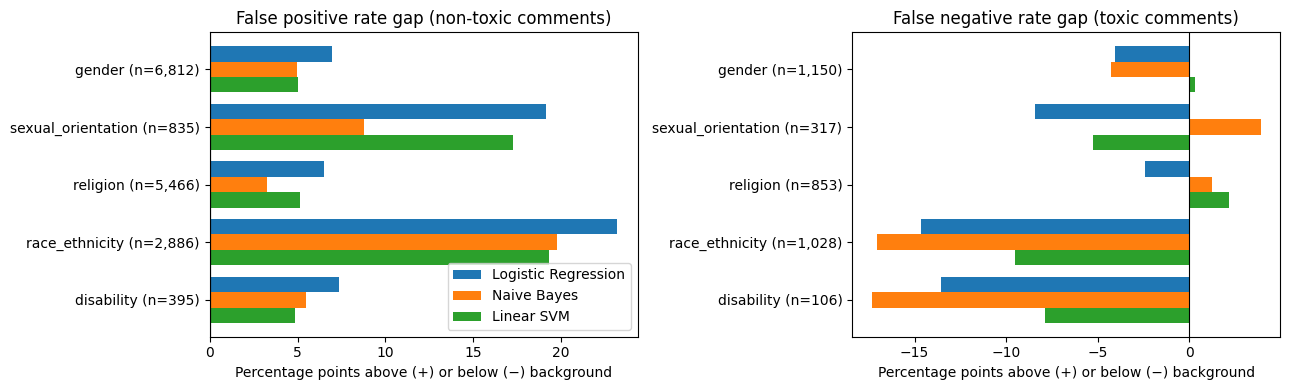

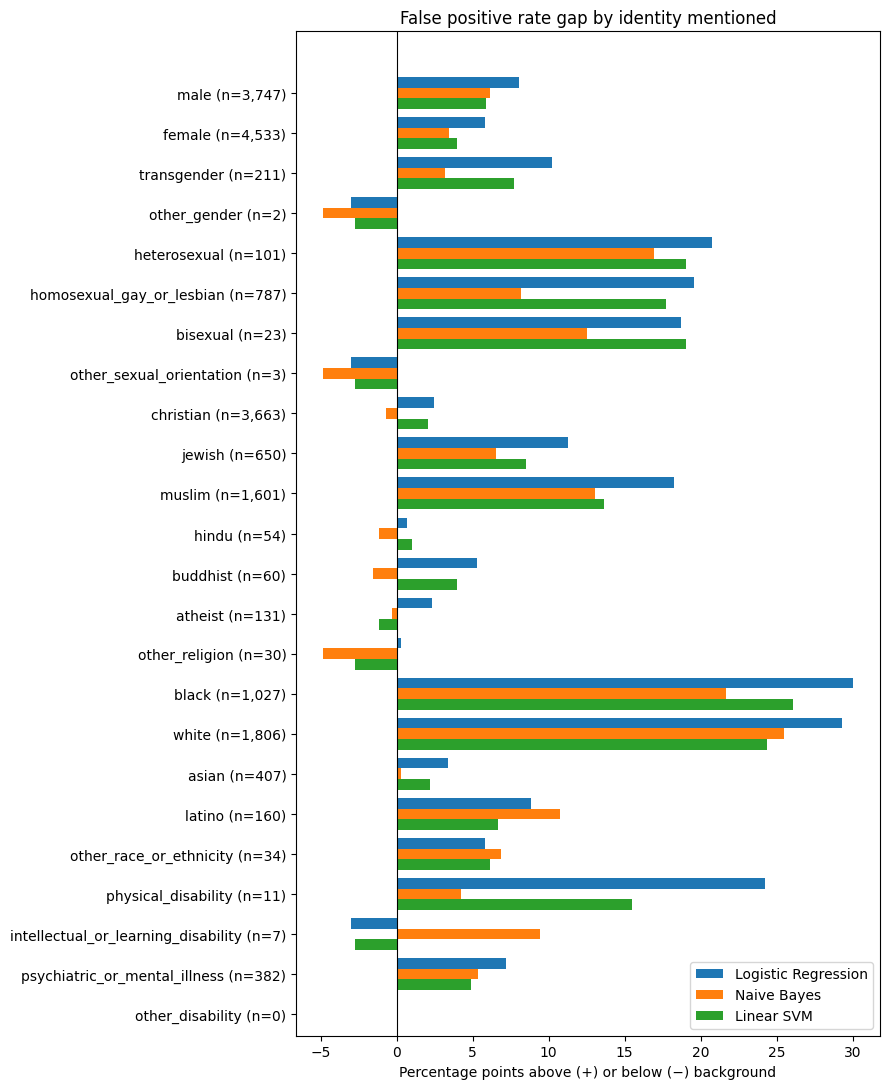

In [ ]:
def plot_gaps(level, metric, ax, title):
    """Grouped bars: each group's rate minus the background rate, one bar per model."""
    sub = rates[rates["level"] == level]
    groups = list(dict.fromkeys(sub["group"]))
    n_col = "n_nontoxic" if metric == "fpr_gap" else "n_toxic"
    sizes = sub.drop_duplicates("group").set_index("group").loc[groups, n_col]
    y = np.arange(len(groups))
    height = 0.8 / len(MODELS)
    for i, model_name in enumerate(MODELS.values()):
        gaps = sub[sub["model"] == model_name].set_index("group").loc[groups, metric]
        ax.barh(y + (i - (len(MODELS) - 1) / 2) * height, gaps * 100, height=height, label=model_name)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{g} (n={n:,})" for g, n in sizes.items()])
    ax.invert_yaxis()
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Percentage points above (+) or below (−) background")
    ax.set_title(title)

# Category level: answers "are racial comments flagged more than gendered ones?"
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_gaps("category", "fpr_gap", axes[0], "False positive rate gap (non-toxic comments)")
plot_gaps("category", "fnr_gap", axes[1], "False negative rate gap (toxic comments)")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

# Individual identities: false positive rate gap
fig, ax = plt.subplots(figsize=(9, 11))
plot_gaps("identity", "fpr_gap", ax, "False positive rate gap by identity mentioned")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [ ]:
def wilson_ci(successes, trials):
    """95% Wilson interval for each successes / trials pair (NaN where trials is 0)."""
    successes = np.asarray(successes, dtype=float)
    trials = np.asarray(trials, dtype=float)
    low = np.full(len(trials), np.nan)
    high = np.full(len(trials), np.nan)
    has_data = trials > 0
    low[has_data], high[has_data] = proportion_confint(successes[has_data], trials[has_data],
                                                       alpha=0.05, method="wilson")
    return np.clip(low, 0, 1), np.clip(high, 0, 1)   # removes tiny rounding errors like -0.0%

rates["fpr_low"], rates["fpr_high"] = wilson_ci(rates["false_pos"], rates["n_nontoxic"])
rates["fnr_low"], rates["fnr_high"] = wilson_ci(rates["false_neg"], rates["n_toxic"])

# Compare each group's interval with the background group's interval for the same model
background = rates[rates["group"] == "background"].set_index("model")

def compare_to_background(metric):
    low, high, value = rates[f"{metric}_low"], rates[f"{metric}_high"], rates[metric]
    bg_low = rates["model"].map(background[f"{metric}_low"])
    bg_high = rates["model"].map(background[f"{metric}_high"])
    return np.select([rates["level"] == "reference", value.isna(), low > bg_high, high < bg_low],
                     ["reference", "no data", "higher", "lower"], default="overlaps")

rates["fpr_vs_background"] = compare_to_background("fpr")
rates["fnr_vs_background"] = compare_to_background("fnr")

rates.to_csv(f"{RESULTS_DIR}/group_error_rates.csv", index=False)   # now includes the intervals

In [ ]:
ARROWS = {"higher": " ▲", "lower": " ▼"}

def ci_table(metric, n_col):
    """Each cell: rate (95% CI), with ▲/▼ when the interval is entirely above/below background."""
    cells = [f"{p:.1%} ({lo:.1%}–{hi:.1%}){ARROWS.get(flag, '')}" if pd.notna(p) else "—"
             for p, lo, hi, flag in zip(rates[metric], rates[f"{metric}_low"],
                                        rates[f"{metric}_high"], rates[f"{metric}_vs_background"])]
    table = rates.assign(cell=cells).pivot(index="group", columns="model", values="cell")
    sizes = rates.drop_duplicates("group").set_index("group")[[n_col]]
    return sizes.join(table[list(MODELS.values())]).loc[list(GROUPS)]

print("False positive rate (95% CI). ▲ = entirely above background, ▼ = entirely below")
display(ci_table("fpr", "n_nontoxic"))

print("False negative rate (95% CI). ▲ = entirely above background, ▼ = entirely below")
display(ci_table("fnr", "n_toxic"))

False positive rate (95% CI). ▲ = entirely above background, ▼ = entirely below


,n_nontoxic,Logistic Regression,Naive Bayes,Linear SVM
group,,,,
overall,35636,6.4% (6.2%–6.7%),7.4% (7.1%–7.7%),5.3% (5.1%–5.6%)
background,21481,3.0% (2.8%–3.3%),4.9% (4.6%–5.2%),2.7% (2.5%–2.9%)
gender,6812,10.0% (9.3%–10.7%) ▲,9.9% (9.2%–10.6%) ▲,7.7% (7.1%–8.4%) ▲
sexual_orientation,835,22.2% (19.5%–25.1%) ▲,13.7% (11.5%–16.1%) ▲,20.0% (17.4%–22.8%) ▲
religion,5466,9.6% (8.8%–10.4%) ▲,8.1% (7.4%–8.9%) ▲,7.8% (7.2%–8.6%) ▲
race_ethnicity,2886,26.2% (24.7%–27.9%) ▲,24.6% (23.1%–26.2%) ▲,22.0% (20.5%–23.6%) ▲
disability,395,10.4% (7.7%–13.8%) ▲,10.4% (7.7%–13.8%) ▲,7.6% (5.4%–10.6%) ▲
male,3747,11.1% (10.1%–12.1%) ▲,11.0% (10.1%–12.1%) ▲,8.6% (7.7%–9.5%) ▲
female,4533,8.8% (8.1%–9.7%) ▲,8.3% (7.5%–9.2%) ▲,6.7% (6.0%–7.4%) ▲


False negative rate (95% CI). ▲ = entirely above background, ▼ = entirely below


,n_toxic,Logistic Regression,Naive Bayes,Linear SVM
group,,,,
overall,4565,36.0% (34.6%–37.4%),45.9% (44.4%–47.3%),37.8% (36.4%–39.2%)
background,1795,39.9% (37.7%–42.2%),49.4% (47.1%–51.7%),39.0% (36.8%–41.3%)
gender,1150,35.9% (33.2%–38.7%),45.1% (42.3%–48.0%),39.3% (36.5%–42.2%)
sexual_orientation,317,31.5% (26.7%–36.9%) ▼,53.3% (47.8%–58.7%),33.8% (28.8%–39.1%)
religion,853,37.5% (34.3%–40.8%),50.6% (47.3%–54.0%),41.1% (37.9%–44.5%)
race_ethnicity,1028,25.3% (22.7%–28.0%) ▼,32.4% (29.6%–35.3%) ▼,29.5% (26.8%–32.3%) ▼
disability,106,26.4% (19.0%–35.5%) ▼,32.1% (24.0%–41.5%) ▼,31.1% (23.1%–40.5%)
male,645,32.7% (29.2%–36.4%) ▼,46.0% (42.2%–49.9%),37.4% (33.7%–41.2%)
female,685,38.1% (34.5%–41.8%),47.3% (43.6%–51.0%),40.7% (37.1%–44.5%)


In [ ]:
for model_name in MODELS.values():
    flagged = rates[(rates["model"] == model_name) & (rates["fpr_vs_background"] == "higher")]
    flagged = flagged.sort_values("fpr_ratio", ascending=False)
    summary = ", ".join(f"{g} ({r:.1f}x)" for g, r in zip(flagged["group"], flagged["fpr_ratio"]))
    print(f"{model_name}: {len(flagged)} groups with FPR clearly above background"
          + (f"\n   {summary}" if summary else ""))

Logistic Regression: 21 groups with FPR clearly above background
   black (10.9x), white (10.6x), physical_disability (8.9x), race_ethnicity (8.6x), heterosexual (7.8x), homosexual_gay_or_lesbian (7.4x), sexual_orientation (7.3x), bisexual (7.1x), muslim (7.0x), jewish (4.7x), transgender (4.4x), latino (3.9x), male (3.6x), disability (3.4x), psychiatric_or_mental_illness (3.3x), gender (3.3x), religion (3.1x), female (2.9x), buddhist (2.7x), asian (2.1x), christian (1.8x)
Naive Bayes: 16 groups with FPR clearly above background
   white (6.2x), black (5.4x), race_ethnicity (5.0x), heterosexual (4.5x), muslim (3.7x), bisexual (3.6x), latino (3.2x), sexual_orientation (2.8x), homosexual_gay_or_lesbian (2.7x), jewish (2.3x), male (2.3x), disability (2.1x), psychiatric_or_mental_illness (2.1x), gender (2.0x), female (1.7x), religion (1.7x)
Linear SVM: 21 groups with FPR clearly above background
   black (10.6x), white (9.9x), race_ethnicity (8.1x), heterosexual (8.0x), bisexual (8.0x), ho

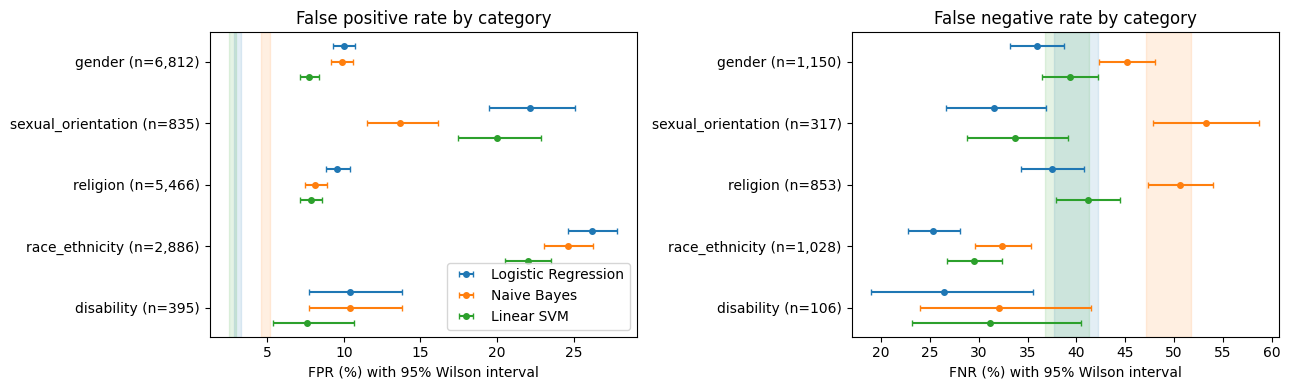

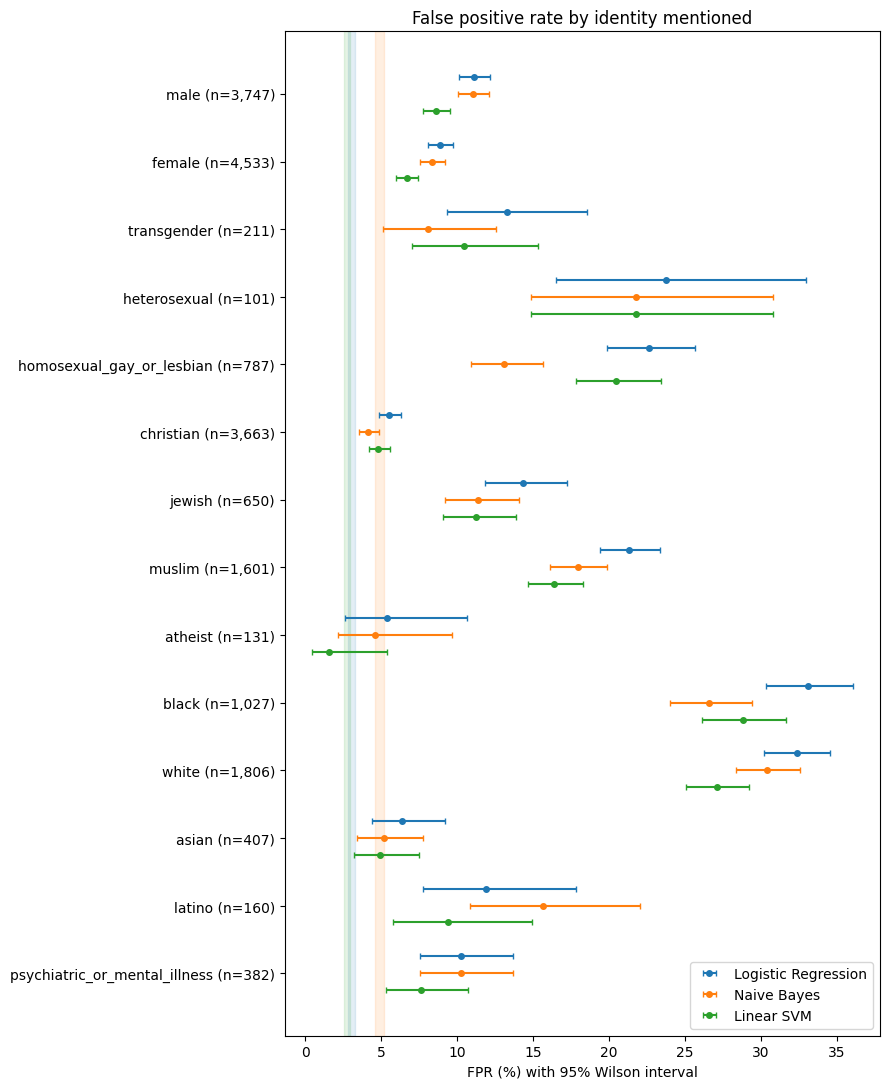

In [ ]:
COLORS = dict(zip(MODELS.values(), plt.rcParams["axes.prop_cycle"].by_key()["color"]))

def plot_ci(level, metric, ax, title, include=None):
    """Each group's rate with its 95% CI, one marker per model; shaded bands are background CIs."""
    sub = rates[rates["level"] == level]
    if include is not None:
        sub = sub[sub["group"].isin(include)]
    groups = list(dict.fromkeys(sub["group"]))
    n_col = "n_nontoxic" if metric == "fpr" else "n_toxic"
    sizes = sub.drop_duplicates("group").set_index("group").loc[groups, n_col]
    y = np.arange(len(groups))
    for i, model_name in enumerate(MODELS.values()):
        m = sub[sub["model"] == model_name].set_index("group").loc[groups]
        err = np.clip([(m[metric] - m[f"{metric}_low"]) * 100,
                       (m[f"{metric}_high"] - m[metric]) * 100], 0, None)
        ax.errorbar(m[metric] * 100, y + (i - (len(MODELS) - 1) / 2) * 0.25, xerr=err,
                    fmt="o", markersize=4, capsize=2, color=COLORS[model_name], label=model_name)
        bg = background.loc[model_name]
        ax.axvspan(bg[f"{metric}_low"] * 100, bg[f"{metric}_high"] * 100,
                   color=COLORS[model_name], alpha=0.12)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{g} (n={n:,})" for g, n in sizes.items()])
    ax.invert_yaxis()
    ax.set_xlabel(f"{metric.upper()} (%) with 95% Wilson interval")
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_ci("category", "fpr", axes[0], "False positive rate by category")
plot_ci("category", "fnr", axes[1], "False negative rate by category")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 11))
plot_ci("identity", "fpr", ax, "False positive rate by identity mentioned", include=reportable)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [ ]:
MIN_NONTOXIC = 100
sizes = rates[rates["level"] == "identity"].drop_duplicates("group").set_index("group")["n_nontoxic"]
reportable = sizes[sizes >= MIN_NONTOXIC].index.tolist()
print(f"Reported individually ({len(reportable)}):", reportable)
print("Too small, covered by their category instead:", sizes[sizes < MIN_NONTOXIC].to_dict())

Reported individually (14): ['male', 'female', 'transgender', 'heterosexual', 'homosexual_gay_or_lesbian', 'christian', 'jewish', 'muslim', 'atheist', 'black', 'white', 'asian', 'latino', 'psychiatric_or_mental_illness']
Too small, covered by their category instead: {'other_gender': 2, 'bisexual': 23, 'other_sexual_orientation': 3, 'hindu': 54, 'buddhist': 60, 'other_religion': 30, 'other_race_or_ethnicity': 34, 'physical_disability': 11, 'intellectual_or_learning_disability': 7, 'other_disability': 0}
